# TOVIS (*TO*nal *VIS*ualization toolbox): _Time Axes_
Johannes Zeitler and Meinard Müller, 2026

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import os

from tovis.feature import compute_chromagram_from_file, compute_chromagram_from_annotations
from tovis.visualization import plot_chromagram, overlay_measure_annotations, overlay_structure_annotations
from tovis.utils import read_csv, time_to_measures, get_tempo_curve

In [2]:
BPSD_DIR = os.path.join("data", "BPSD")

piece = "Beethoven_Op014No2-01"
versions = ["AS35", "FG58", "WK64"]

path_audio = os.path.join(BPSD_DIR, "1_Audio")
path_audio_measure = os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_measure")
path_audio_structure = os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_structureCoarse")
path_score_structure = os.path.join(BPSD_DIR, "2_Annotations", "ann_score_structureCoarse")
path_audio_note = os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_note")

Different audio recordings are performed at different tempi

In [4]:
print("Recording duration: ")
max_duration = 0
for version in versions:
    duration = librosa.get_duration(path=os.path.join(path_audio, piece+"_"+version+".mp3"))
    max_duration = max([max_duration, duration])
    print("- %s: %.1fs"%(version, duration))

Recording duration: 
- AS35: 349.5s
- FG58: 437.7s
- WK64: 449.0s


In our first example, we compute features that follow the physical time axis of each recording. We can then compare features for different versions on their individual time axes. We see that the pieces are performed with vastly different tempi.

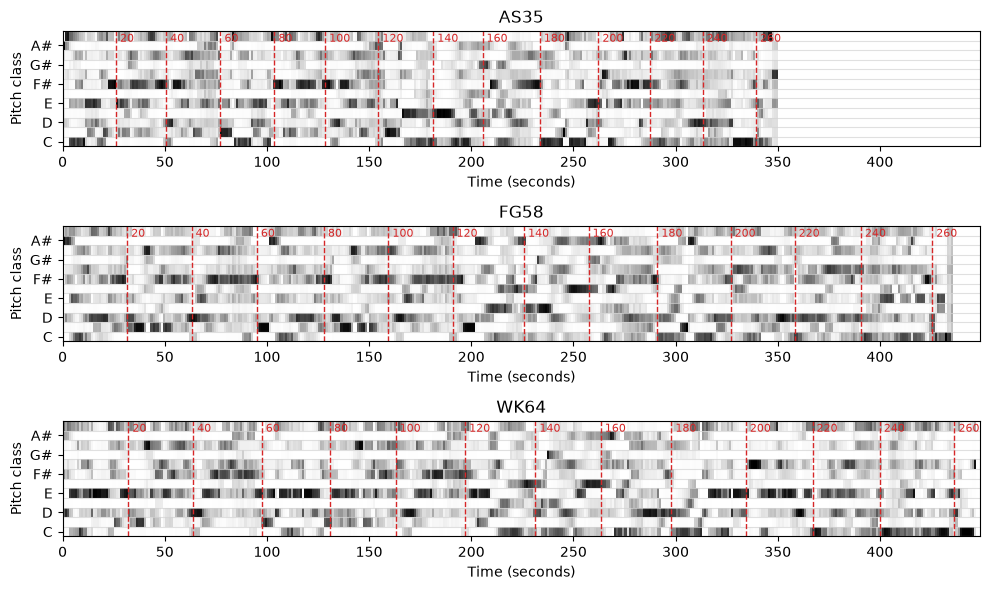

In [5]:
fig, ax = plt.subplots(len(versions), 1, figsize=(10, 2*len(versions)))

for i, version in enumerate(versions):
    chromagram, sr_chromagram = compute_chromagram_from_file(os.path.join(path_audio, piece+"_"+version+".mp3"),
                                                             backend="IIR", smoothing_length_seconds=4, output_feature_rate=1,
                                                             norm="2")    
    plot_chromagram(chromagram, feature_rate=sr_chromagram, ax=ax[i], title=version, ytick_label_hop=2, colorbar=False,
                    xlim=[0, max_duration])

    overlay_measure_annotations(filename=os.path.join(path_audio_measure, piece + "_" + version + ".csv"),
                                ax=ax[i], measure_annotation_hop=20, label_location="top")
    

fig.tight_layout()
plt.show()

To analyze these tempi, we compute tempo curves. Intuitively, we compute the tempo as measures per second. A higher value means higher tempo. We can plot these tempo curves over a physical time axis (in seconds) and over a musical time axis (in measures). The latter is suited for direct comparison and averaging operations, e.g., computing a mean tempo.

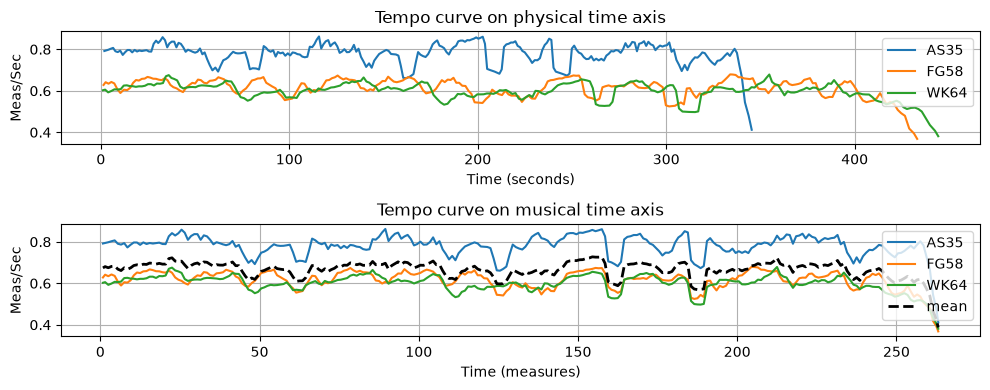

In [7]:
colors = ["tab:blue", "tab:orange", "tab:green"]
tempo_curves = []

fig, ax = plt.subplots(2,1, figsize=(10,4))
for version, color in zip(versions, colors):
    ann_audio_measure = read_csv(os.path.join(path_audio_measure, piece + "_" + version + ".csv"))

    axis_seconds, axis_measures, tempo_curve = get_tempo_curve(ann_audio_measure, smoothing_length_measures=5,
                                                               smoothing_method="mean")

    tempo_curves.append(tempo_curve)

    ax[0].plot(axis_seconds, tempo_curve, label=version)
    ax[1].plot(axis_measures, tempo_curve, label=version)


ax[1].plot(axis_measures, np.mean(np.array(tempo_curves), axis=0), color="k", linewidth=2, linestyle="--", label="mean")

ax[0].set_xlabel("Time (seconds)")
ax[0].grid()
ax[0].legend()
ax[0].set_ylabel("Meas/Sec")
ax[0].set_title("Tempo curve on physical time axis")

ax[1].set_xlabel("Time (measures)")
ax[1].grid()
ax[1].legend()
ax[1].set_ylabel("Meas/Sec")
ax[1].set_title("Tempo curve on musical time axis")

fig.tight_layout()
plt.show()

We have now seen the problem of different tempi in audio recordings when it comes to visualization and comparison of features. If we want to compare audio features of different versions, we can bring them to a common time axis - the musical time axis, where time is counted in measures. This time conversion relies on measure annotations for each version. 

Having a common time axis allows for further analysis methods, such as an overlay of features for different versions.

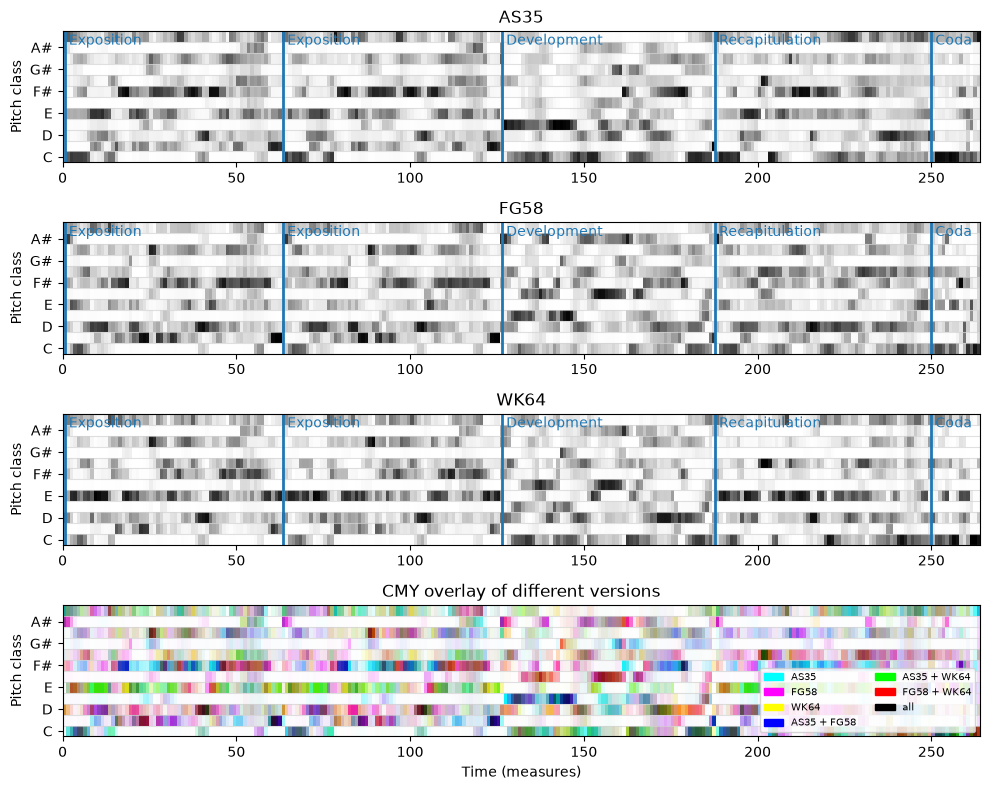

In [8]:
fig, ax = plt.subplots(len(versions)+1, 1, figsize=(10, 2*len(versions)+2))

frames_per_measure=1

chromagrams_musical_time = []
for i, version in enumerate(versions):
    chromagram, sr_chromagram = compute_chromagram_from_file(os.path.join(path_audio, piece+"_"+version+".mp3"),
                                                             backend="IIR", smoothing_length_seconds=4, output_feature_rate=1,
                                                             norm="2")            
    ann_audio_measure = read_csv(os.path.join(path_audio_measure, piece + "_" + version + ".csv"))    
    chromagram_musical_time, musical_time_axis = time_to_measures(chromagram, sync_annotation=ann_audio_measure, feature_rate=sr_chromagram,
                                               frames_per_measure=frames_per_measure)
    chromagrams_musical_time.append(chromagram_musical_time)
    plot_chromagram(chromagram_musical_time, feature_rate=frames_per_measure, ax=ax[i], title=version, ytick_label_hop=2, colorbar=False,
                    xlabel=None)        
    overlay_structure_annotations(filename=os.path.join(path_score_structure, piece + ".csv"), ax=ax[i])

plot_chromagram(chromagrams_musical_time, feature_rate=frames_per_measure, ytick_label_hop=2, overlay_labels=versions,
                ax=ax[-1], title="CMY overlay of different versions")

ax[-1].set_xlabel("Time (measures)")
fig.tight_layout()
plt.show()

Last, we compare features obtained from audio recordings against features from the symbolic score. Again, these features can be represented on a physical time axis (in seconds) and a musical time axis (in measures).

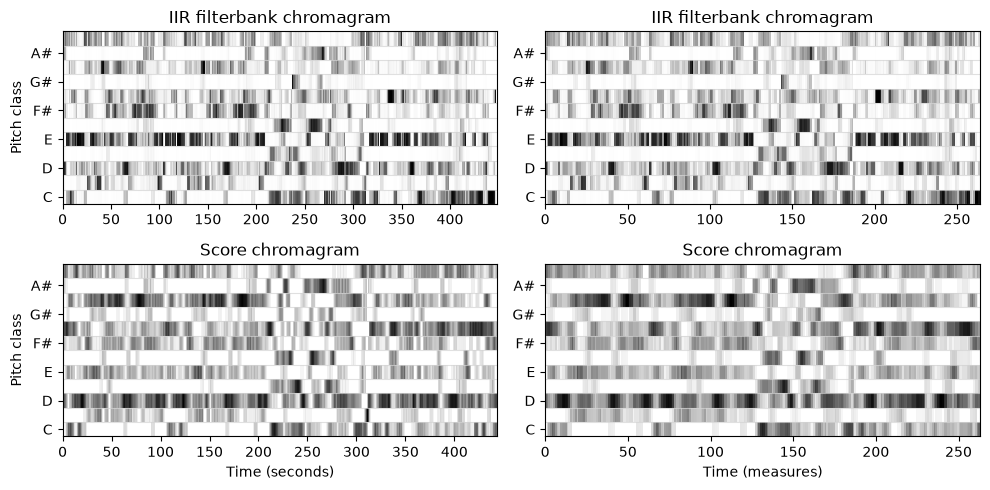

In [9]:
version = "WK64"

chromagram_IIR, sr_chromagram_IIR = compute_chromagram_from_file(os.path.join(path_audio, piece+"_"+version+".mp3"),
                                                             backend="IIR", smoothing_length_seconds=4, output_feature_rate=1,
                                                             norm="2")            
ann_audio_measure = read_csv(os.path.join(path_audio_measure, piece + "_" + version + ".csv"))    
chromagram_IIR_musical_time, musical_time_axis = time_to_measures(chromagram_IIR, sync_annotation=ann_audio_measure, feature_rate=sr_chromagram,
                                            frames_per_measure=frames_per_measure)


chromagram_score_physical_time, _ = compute_chromagram_from_annotations(filename = os.path.join(path_audio_note , piece + "_" + version + ".csv"),
                                                       feature_rate=sr_chromagram_IIR,
                                                       start_column="start", end_column="end",
                                                       smoothing_length_seconds=4, output_feature_rate=sr_chromagram_IIR)

chromagram_score_musical_time, _ = compute_chromagram_from_annotations(filename=os.path.join(path_audio_note , piece + "_" + version + ".csv"),
                                                       feature_rate=frames_per_measure,
                                                       start_column="start_meas", end_column="end_meas",
                                                       smoothing_length_seconds=4, output_feature_rate=frames_per_measure)


fig, ax = plt.subplots(2,2, figsize=(10,5))

plot_chromagram(chromagram_IIR, feature_rate=sr_chromagram_IIR,colorbar=False, ytick_label_hop=2,
                ax=ax[0,0], xlabel=None, title="IIR filterbank chromagram")
plot_chromagram(chromagram_score_physical_time, feature_rate=sr_chromagram_IIR,colorbar=False, ytick_label_hop=2,
                ax=ax[1,0], title="Score chromagram", xlabel="Time (seconds)")

plot_chromagram(chromagram_IIR_musical_time, feature_rate=frames_per_measure,colorbar=False, ytick_label_hop=2,
                ax=ax[0,1], title="IIR filterbank chromagram", xlabel=None, ylabel=None)
plot_chromagram(chromagram_score_musical_time, feature_rate=frames_per_measure,colorbar=False, ytick_label_hop=2,
                ax=ax[1,1], title="Score chromagram", xlabel="Time (measures)", ylabel=None)

fig.tight_layout()
plt.show()